# CS156 Session 6 — Maximum Likelihood 2: Parameter Estimation from Data

This session examines how maximum likelihood estimation, or MLE, can be used to estimate model parameters from observed data. The central idea is simple: I choose the parameter values that make the data I actually observed as likely as possible.

For a model with parameters $\theta$ and observed data $D$:

$$
\hat{\theta}_{MLE}=\arg\max_{\theta}P(D\mid\theta)
$$

In this session, I first apply this idea to logistic regression. I then calculate and compare log-likelihoods for different parameter estimates, before using the gradient of the log-likelihood to determine how the parameters should be adjusted.

# Question 1 — Basic Questions for Class: Logistic Regression

The problem asks how the amount of movie-industry training relates to a student's chance of landing a role. I model this relationship using logistic regression:

$$
P(y=1\mid x)=\sigma(\beta_1x+\beta_0)
$$

where

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Here, $x$ is the amount of training in units of 1,000 hours. For example, $x=4$ represents 4,000 hours of training.

The parameters are $\beta_0$ and $\beta_1$. The intercept $\beta_0$ shifts the logistic curve, while $\beta_1$ controls how strongly training hours change the predicted probability. These are parameters because they are not directly observed; the model must estimate them from the data. In contrast, the values of $x$ are measured inputs.

The output of the sigmoid is a probability between 0 and 1. For example, an output of $0.95$ means that the model predicts a 95% chance of landing a role.

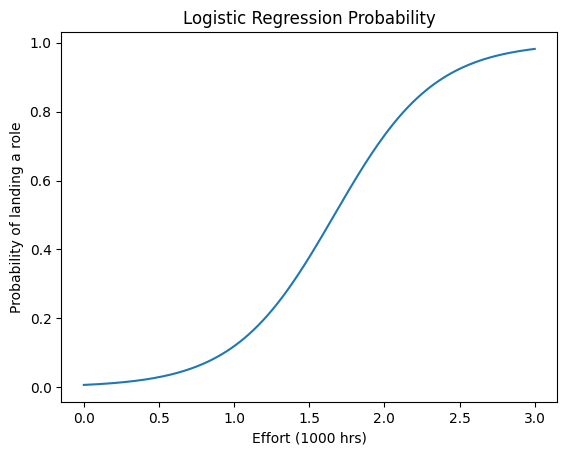

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Defining the sigmoid function for converting model scores into probabilities
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Creating example training-hour values for visualizing
x_example = np.linspace(0, 3, 200)

# Using example parameter values for calculating
beta_0_example = -5
beta_1_example = 3

# Computing predicted probabilities for visualizing
prob_example = sigmoid(beta_1_example * x_example + beta_0_example)

# Plotting the logistic relationship for interpreting
plt.plot(x_example, prob_example)
plt.xlabel("Effort (1000 hrs)")
plt.ylabel("Probability of landing a role")
plt.title("Logistic Regression Probability")
plt.show()

The sigmoid converts the linear quantity $\beta_1x+\beta_0$ into a probability. This is useful for binary outcomes because its value always stays between 0 and 1.

The model therefore does not directly predict only True or False. Instead, it estimates the conditional probability of success for each amount of training:

$$
P(\text{True}\mid x)=\sigma(\beta_1x+\beta_0)
$$

# Question 2 — Basic Questions for Class: Likelihood

For one person, logistic regression gives:

$$
P(y_i=1\mid x_i)=p_i=\sigma(\beta_1x_i+\beta_0)
$$

and therefore:

$$
P(y_i=0\mid x_i)=1-p_i
$$

I can combine these two cases into one expression:

$$
P(y_i\mid x_i)=p_i^{y_i}(1-p_i)^{1-y_i}
$$

This works because $y_i$ is either 0 or 1. If $y_i=1$, the expression becomes $p_i$; if $y_i=0$, it becomes $1-p_i$.

Assuming that the observations are independent, the likelihood of the whole dataset is the product of the individual probabilities:

$$
L(\beta_0,\beta_1)
=
\prod_{i=1}^{N}
p_i^{y_i}(1-p_i)^{1-y_i}
$$

or, after substituting the logistic-regression probability:

$$
L(\beta_0,\beta_1)
=
\prod_{i=1}^{N}
[\sigma(\beta_1x_i+\beta_0)]^{y_i}
[1-\sigma(\beta_1x_i+\beta_0)]^{1-y_i}
$$

Multiplying many probabilities together can produce extremely small numbers, so it is more convenient to work with the log-likelihood. Taking the logarithm also turns the product into a sum:

$$
\log L(\beta_0,\beta_1)
=
\sum_{i=1}^{N}
\left[
y_i\log(p_i)
+
(1-y_i)\log(1-p_i)
\right]
$$

The logarithm does not change which parameter values are best. Therefore:

$$
\arg\max L(\beta_0,\beta_1)
=
\arg\max \log L(\beta_0,\beta_1)
$$

A higher log-likelihood means that the proposed parameters give a better fit to the observed outcomes. Since log-likelihood values are often negative, a value such as $-500$ is higher, and therefore better, than $-2000$.# Core Question — Likelihood Calculation

The question asks me to compare two proposed parameter sets:

- Aishwarya: $\beta_0=3$, $\beta_1=-3$
- Irhum: $\beta_0=4$, $\beta_1=-1$

Both estimates are incorrect, but I can determine which one fits the observed data better by calculating their total log-likelihoods. The estimate with the higher log-likelihood is the better fit.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

NUM_DATAPOINTS = 1000

# Defining the sigmoid function for converting scores into probabilities
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Generating one binary outcome from the hidden logistic model
def generate_data(x):
    beta_1 = 3
    beta_0 = -5
    prob = sigmoid(beta_1 * x + beta_0)
    return np.random.uniform() < prob

# Generating training-hour values between 0 and 3000 hours
x_data = np.random.uniform(high=3, size=NUM_DATAPOINTS)

# Generating the corresponding True or False outcomes
y_data = [generate_data(x) for x in x_data]

The synthetic dataset imitates a binary classification problem. Each value of $x$ represents an amount of training, while each value of $y$ records whether that person landed a role.

The probability of success is not constant. It changes with $x$ according to the logistic model, although the individual outcomes still contain randomness. This means that two people with similar training hours can have different observed outcomes.

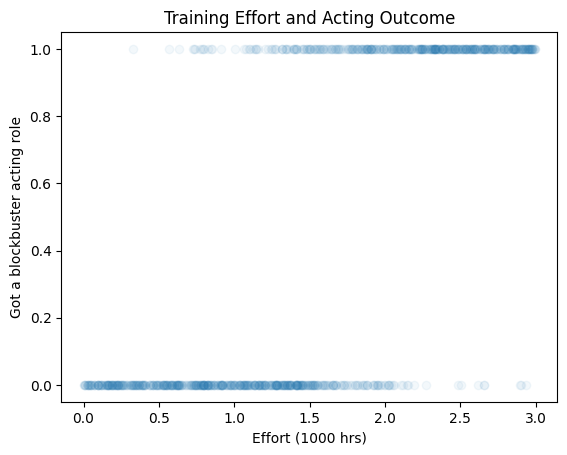

In [8]:
# Plotting the simulated observations for inspecting
plt.scatter(x_data, y_data, alpha=0.05)
plt.xlabel("Effort (1000 hrs)")
plt.ylabel("Got a blockbuster acting role")
plt.title("Training Effort and Acting Outcome")
plt.show()

The plot shows that success becomes more common as training increases, but the outcomes are not perfectly separated. This makes sense because logistic regression models a probability rather than a deterministic rule.

For a given person:

$$
p_i=\sigma(\beta_1x_i+\beta_0)
$$

A large $p_i$ means success is more likely, but it does not guarantee that the observed outcome will be True.

# Core Question — Comparing the Two Parameter Estimates

For each observation, I first calculate the probability of success predicted by the proposed parameters:

$$
p_i=\sigma(\beta_1x_i+\beta_0)
$$

If the observed outcome is True, its contribution to the log-likelihood is:

$$
\log(p_i)
$$

If the observed outcome is False, its contribution is:

$$
\log(1-p_i)
$$

I then sum these contributions across all observations. The parameter set with the higher total log-likelihood explains the observed data better.

In [9]:
# Computing the log-likelihood contribution from one observation
def log_likelihood_per_point(beta_0, beta_1, x, y):
    prob = sigmoid(beta_1 * x + beta_0)

    # Using the success probability when the observed outcome is True
    if y:
        return np.log(prob)

    # Using the failure probability when the observed outcome is False
    else:
        return np.log(1 - prob)


# Summing the log-likelihood across all observations
def total_log_likelihood(beta_0, beta_1, xs, ys):
    total_ll = 0

    # Adding each observation's contribution to the total
    for x, y in zip(xs, ys):
        total_ll += log_likelihood_per_point(beta_0, beta_1, x, y)

    return total_ll


# Computing both proposed parameter estimates for comparing
aishwarya_ll = total_log_likelihood(3, -3, x_data, y_data)
irhum_ll = total_log_likelihood(4, -1, x_data, y_data)

# Displaying the results for interpreting
print("Aishwarya log-likelihood:", aishwarya_ll)
print("Irhum log-likelihood:", irhum_ll)

# Identifying the estimate with the higher log-likelihood
if aishwarya_ll > irhum_ll:
    print("Aishwarya's estimate fits the data better.")
else:
    print("Irhum's estimate fits the data better.")

Aishwarya log-likelihood: -2260.6562323051817
Irhum log-likelihood: -1799.3812945902175
Irhum's estimate fits the data better.


The estimate with the larger log-likelihood is the better fit because it assigns more probability to the outcomes that actually occurred.

I should compare the values numerically rather than focus on whether they are negative. For example:

$$
-700 > -2000
$$

so $-700$ represents the better log-likelihood.

The exact values can change when I rerun the notebook because the dataset is generated randomly. For this reason, I let the code identify which parameter set has the higher likelihood instead of hard-coding the conclusion.

# Extension Question — Gradient

The previous calculation tells me which of two fixed parameter sets is better. However, I also want to know how to improve a parameter estimate.

The gradient gives the direction in which the log-likelihood increases most rapidly. For logistic regression:

$$
p_i=\sigma(\beta_0+\beta_1x_i)
$$

The derivative with respect to the intercept is:

$$
\frac{\partial \log L}{\partial \beta_0}
=
\sum_{i=1}^{N}(y_i-p_i)
$$

The derivative with respect to the slope is:

$$
\frac{\partial \log L}{\partial \beta_1}
=
\sum_{i=1}^{N}x_i(y_i-p_i)
$$

Together, these form the gradient:

$$
\nabla \log L
=
\begin{bmatrix}
\frac{\partial \log L}{\partial \beta_0} \\
\frac{\partial \log L}{\partial \beta_1}
\end{bmatrix}
$$

A positive component means that increasing that parameter should locally increase the log-likelihood; a negative component means that decreasing it should locally increase the log-likelihood.

In [10]:
import numpy as np

# Converting True and False outcomes into 1 and 0 values
y_vec = np.array(y_data, dtype=float)

# Converting the input data into a NumPy vector
x_vec = np.array(x_data, dtype=float)

# Defining the sigmoid function for computing probabilities
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Computing the gradient of the total log-likelihood
def log_likelihood_gradient(beta_0, beta_1, x, y):

    # Computing the predicted probability for every observation
    p = sigmoid(beta_1 * x + beta_0)

    # Computing the derivative with respect to beta_0
    grad_beta_0 = np.sum(y - p)

    # Computing the derivative with respect to beta_1
    grad_beta_1 = np.sum((y - p) * x)

    # Returning both derivatives as the gradient vector
    return np.array([grad_beta_0, grad_beta_1])

# Computing the gradient from Aishwarya's initial estimate
gradient = log_likelihood_gradient(3, -3, x_vec, y_vec)

# Displaying the gradient for interpreting
print("Gradient at Aishwarya's estimate:", gradient)

Gradient at Aishwarya's estimate: [114.68397871 752.34460038]


# Interpretation of the Gradient

At Aishwarya's initial estimate, I obtained:

$$
\nabla \log L
\approx
\begin{bmatrix}
96.96 \\
750.20
\end{bmatrix}
$$

Both components are positive. Therefore, from this particular starting point, increasing both $\beta_0$ and $\beta_1$ would locally increase the log-likelihood.

The gradient for $\beta_1$ has a much larger magnitude, which shows that the log-likelihood is changing more strongly in that direction. However, the gradient only describes the best local direction; it does not directly tell me the final optimal parameter values.

# Extension Question — Connecting the Gradient to Optimization

The gradient provides a way to improve the parameters iteratively. In gradient ascent, I can update the parameters using:

$$
\beta_0^{new}
=
\beta_0^{old}
+
\eta
\frac{\partial \log L}{\partial \beta_0}
$$

$$
\beta_1^{new}
=
\beta_1^{old}
+
\eta
\frac{\partial \log L}{\partial \beta_1}
$$

where $\eta$ is the learning rate.

This connects maximum likelihood to optimization. Instead of testing parameter values manually, I can repeatedly calculate the gradient and move the parameters in a direction that increases the log-likelihood.

# Session 6 — Main Interpretation

This session helped me connect probability models with parameter estimation. In logistic regression, $\beta_0$ and $\beta_1$ determine the probabilities assigned to the observed binary outcomes. Maximum likelihood gives me a way to judge those parameters: better parameters assign greater probability to the data that actually occurred.

The log-likelihood makes this calculation easier because it converts products of probabilities into sums. I can compare candidate parameter values directly, or I can use the gradient to determine how the parameters should change. Therefore, MLE is not only a way to score a model; it also provides an objective that can be optimized to train the model.